# SYNDRI-SIM: optimized donor-pool-fraction admixture

Figure panels for the new simulation: **K = 9**, frozen donor-type weights,
and **λ_max = 0.25**, with per-cell λ sampled uniformly from [0, λ_max].
The target addition is `round(λ × eligible weighted donor-pool counts)`;
eligible whole genes are added in random order. Native, added, and combined
counts are preserved in the saved test slices.

The notebook reproduces the MMD, ROC, PR, AUPRC, F1, removal, marker-gene
co-detection, and directed adjacency panels. The method-comparison panels
await **fresh predictions for these exact inputs**; they never use predictions
or metric caches from the original tau simulation. No inference or training
jobs are launched by this notebook.

**Calibration and evaluation are separate.** Lambda was selected using only
Lung5_Rep1–3 training/calibration data. Held-out test MMD and method performance
below are post-selection evaluations of the saved test data.


In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display
import seaborn as sns
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

font_path = '/home/jwinchel/fonts/ARIAL.TTF'  
fm.fontManager.addfont(font_path)
mpl.rcParams['svg.fonttype'] = 'none'
# Set Arial globally
plt.rcParams['font.family'] = 'Arial'
# sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,

})

REPO = Path('/home/jwinchel/Syndri')
DATA_ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx')
BENCHMARK_ROOT = REPO / 'outputs' / 'SyndriSIM_pool_fraction'
SPATIAL_DIR = DATA_ROOT / 'results' / 'final'
REFERENCE_PATH = DATA_ROOT / 'spillover-benchmark/test_admixture/train_val_sc_reference_unique.h5ad'
FIGURE_DIR = REPO / 'figures' / 'outputs' / 'Figure3_SyndriSIM_PoolFraction'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

COMPARISON_SLICE = 'Lung12'  # Lung12, Lung13, Lung9_Rep1, or Lung9_Rep2.
MAX_QUERY_PER_CELL_TYPE = 500
MMD_QUERY_SEED = 91827
SYNDRI_REMOVAL_THRESHOLD = 0.5
OVRLPY_VSI_THRESHOLD = 0.7  # Saved pixel-VSI corrections: 0.5 or 0.7.
REQUIRE_COMPLETE_METHODS = True  # All four prediction slices before comparing a method.
# Empty set reuses matching caches. Add only the groups you want to rebuild:
# 'test_mmd', 'method_metrics', 'coexpression_matrix', 'cell_type_adjacency'.
RESULTS_TO_RECOMPUTE = set()
VALID_RESULT_GROUPS = {'test_mmd', 'method_metrics', 'coexpression_matrix', 'cell_type_adjacency'}
if RESULTS_TO_RECOMPUTE - VALID_RESULT_GROUPS:
    raise ValueError(f'Unknown cache groups: {RESULTS_TO_RECOMPUTE - VALID_RESULT_GROUPS}')
if not 0 <= SYNDRI_REMOVAL_THRESHOLD <= 1:
    raise ValueError('SYNDRI_REMOVAL_THRESHOLD must be in [0,1]')

sys.path.insert(0, str(REPO / 'scripts' / 'spillover-benchmark'))
import importlib
import pool_fraction_figure_data
importlib.reload(pool_fraction_figure_data)
from pool_fraction_figure_data import (
    calibration_mmd, test_mmd, availability, benchmark_metrics, adjacency,
    METHODS as method_order, PR_METHODS as pr_method_order,
)
font_path = REPO.parent / 'fonts' / 'ARIAL.TTF'
if font_path.exists():
    fm.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = 'Arial'
plt.rcParams.update({'font.size': 8, 'axes.labelsize': 8, 'xtick.labelsize': 8,
    'ytick.labelsize': 8, 'axes.titlesize': 10, 'svg.fonttype': 'none'})
curve_colors = {'Raw': '#4C72B0', 'ResolVI': '#C44E52', 'ResolVI (binarized)': '#E3A6A9',
    'Syndri': '#DD8452', 'Syndri (binarized)': '#EFC4A5', 'SPLIT': '#55A868', 'SPLIT (binarized)': '#AFD2B5',
    'CellAdmix': '#8172B3', 'CellAdmix (binarized)': '#C0B8D9',
    'ovrlpy': '#937860', 'ovrlpy (binarized)': '#C9BBB0'}

selection = json.loads((BENCHMARK_ROOT / 'search' / 'selected_parameters.json').read_text())
print(f"Selected lambda_max={selection['lambda_max']:g}; calibration MMD²={selection['mean_mmd2']:.5f}")
print(f'New simulation inputs: {BENCHMARK_ROOT / "slices"}')
print(f'Figure outputs and independent caches: {FIGURE_DIR}')

def save_panel(fig, stem):
    for extension in ['png', 'pdf', 'svg']:
        fig.savefig(FIGURE_DIR / f'{stem}.{extension}', dpi=400, bbox_inches='tight')

def macro_mmd(frame):
    return frame.groupby('slice')[['mmd2_before', 'mmd2_after_mean']].mean().mean()

def awaiting(ax, text='Awaiting fresh\nmethod predictions'):
    ax.text(.5, .5, text, ha='center', va='center', transform=ax.transAxes, fontsize=8, color='0.45')


Selected lambda_max=0.25; calibration MMD²=0.06912
New simulation inputs: /home/jwinchel/Syndri/outputs/SyndriSIM_pool_fraction/slices
Figure outputs and independent caches: /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_PoolFraction


## Calibration MMD²: the selected lambda

Reuse the search's exact scores and fixed evaluation design: 500 fixed cells
per supported type/slice; CP10K then log1p over 956 genes; RBF bandwidth fixed
per slice/type using clean and real counts. Each plotted point represents a
cell-type stratum. After-admixture values average three simulation seeds.
The boxplot retains one hue per Lung5 replicate. Lower MMD² is better.


In [2]:
calibration_summary = calibration_mmd(BENCHMARK_ROOT)
calibration_summary.to_csv(FIGURE_DIR / 'calibration_mmd_by_slice_celltype.csv', index=False)
display(calibration_summary.groupby('slice')[['mmd2_before', 'mmd2_after_mean']].mean())
print('Equal type/slice means:', macro_mmd(calibration_summary).to_dict())


,mmd2_before,mmd2_after_mean
slice,,
Lung5_Rep1,0.103006,0.071400
Lung5_Rep2,0.100547,0.067742
Lung5_Rep3,0.097358,0.068221


Equal type/slice means: {'mmd2_before': 0.10030383624096034, 'mmd2_after_mean': 0.06912095180026943}


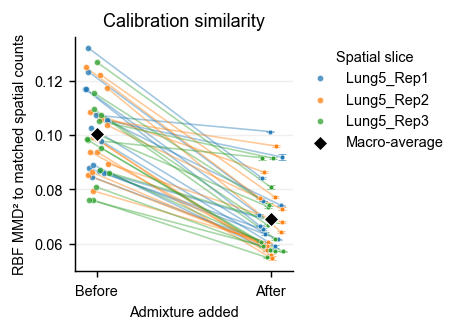

Equal-weight mean across slice/cell-type strata: 0.1003 before, 0.0691 after
Relative change: -31.1%


In [3]:
summary = calibration_summary
slice_names = sorted(summary["slice"].unique())
# Paired stratum-level values; lower MMD² means closer to the real spatial counts.
fig, ax = plt.subplots(figsize=(3.6, 2.6))
x_before, x_after = 0, 1
slice_colors = dict(zip(slice_names, plt.get_cmap("tab10").colors))
rng = np.random.default_rng(1729)
for slice_name, group in summary.groupby("slice", sort=True):
    jitter = rng.uniform(-0.07, 0.07, size=len(group))
    color = slice_colors[slice_name]
    for j, (_, row) in enumerate(group.iterrows()):
        ax.plot([x_before + jitter[j], x_after + jitter[j]],
                [row.mmd2_before, row.mmd2_after_mean],
                color=color, alpha=0.42, linewidth=0.9, zorder=1)
    ax.scatter(x_before + jitter, group.mmd2_before, color=color, s=12,
               alpha=0.75, edgecolor="white", linewidth=0.35, label=slice_name, zorder=2)
    ax.errorbar(x_after + jitter, group.mmd2_after_mean,
                yerr=group.mmd2_after_sd, fmt="o", color=color,
                markersize=2.7, capsize=2, alpha=0.85,
                markeredgecolor="white", markeredgewidth=0.35, zorder=3)

overall_before = macro_mmd(summary).mmd2_before
overall_after = macro_mmd(summary).mmd2_after_mean
ax.scatter([x_before, x_after], [overall_before, overall_after],
           marker="D", s=35, color="black", edgecolor="white",
           linewidth=0.8, label="Macro-average", zorder=5)
ax.set_xticks([x_before, x_after], ["Before", "After"])
ax.set_ylabel("RBF MMD² to matched spatial counts", fontsize=8)
ax.set_xlabel("Admixture added", fontsize=8)
ax.set_title("Calibration similarity", fontsize=10)
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="both", labelsize=8)
ax.legend(title="Spatial slice", frameon=False, fontsize=8, title_fontsize=8,
          loc="upper left", bbox_to_anchor=(1.0,1.))
fig.tight_layout()
save_panel(fig, 'calibration_mmd_paired')
plt.show()
print(f"Equal-weight mean across slice/cell-type strata: {overall_before:.4f} before, {overall_after:.4f} after")
print(f"Relative change: {(overall_after / overall_before - 1) * 100:.1f}%")


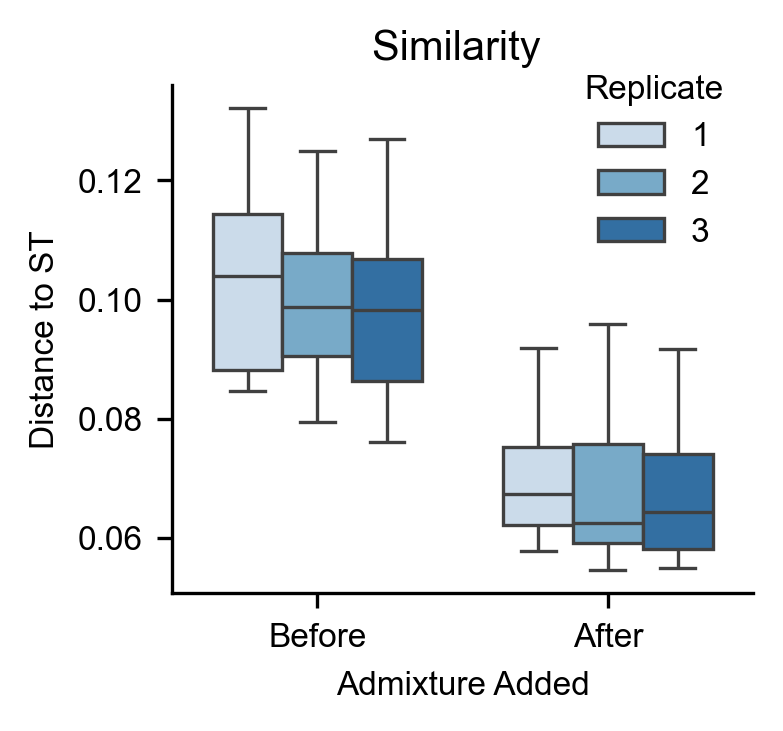

In [4]:
boxplot_long = calibration_summary.melt(id_vars='slice', value_vars=['mmd2_before', 'mmd2_after_mean'],
    var_name='phase', value_name='mmd2')
boxplot_long['phase'] = boxplot_long.phase.map({'mmd2_before': 'Before', 'mmd2_after_mean': 'After'})
boxplot_long['replicate'] = boxplot_long['slice'].str.extract(r'Rep(\d+)', expand=False)
replicate_order = ['1','2','3']
fig, ax = plt.subplots(figsize=(2.5, 2.2), dpi=300)
sns.boxplot(
    data=boxplot_long, x="phase", y="mmd2", hue="replicate",
    order=["Before", "After"],
    hue_order=replicate_order, palette='Blues',
    showfliers=False, width=0.72, linewidth=0.8, ax=ax,
)
ax.set(xlabel="", ylabel="Distance to ST",
       )
ax.set_title("Similarity ", fontsize=10)
ax.tick_params(axis="both", labelsize=8)
ax.set_xlabel("Admixture Added", fontsize=8)
ax.set_ylabel(ax.get_ylabel(), fontsize=8)
ax.grid(False, axis="x")
ax.grid(False, axis="y")
ax.legend(title="Replicate", frameon=False, loc="center right", fontsize=8, title_fontsize=8,bbox_to_anchor=(1.0,0.85))
# fig.tight_layout()
fig.savefig(FIGURE_DIR / "Figure3_SyndriSIM_MMD_boxplot.png", dpi=300, bbox_inches="tight")
fig.savefig(FIGURE_DIR / "Figure3_distToST.svg")
plt.show()
save_panel(fig, 'calibration_mmd_boxplot')
plt.show()


## Held-out test MMD²

Evaluate the **saved** clean and admixed test matrices against their matched
real CosMx cells. Use up to 500 fixed cells per type and slice. Preprocessing
and the RBF definition match calibration, with a clean/real bandwidth fixed
within each test stratum for the before/after comparison. These values are
not used to select lambda. There is one saved synthetic realization per test
slice, so no simulation-seed SD is inferred for these panels.


In [5]:
test_summary = test_mmd(BENCHMARK_ROOT, SPATIAL_DIR, FIGURE_DIR,
    max_queries=MAX_QUERY_PER_CELL_TYPE, query_seed=MMD_QUERY_SEED,
    recompute='test_mmd' in RESULTS_TO_RECOMPUTE)
display(test_summary.groupby('slice')[['mmd2_before', 'mmd2_after_mean']].mean())
print('Held-out equal type/slice means:', macro_mmd(test_summary).to_dict())


,mmd2_before,mmd2_after_mean
slice,,
Lung12,0.146761,0.095966
Lung13,0.114352,0.073183
Lung9_Rep1,0.123377,0.077537
Lung9_Rep2,0.163132,0.100497


Held-out equal type/slice means: {'mmd2_before': 0.13690576241325958, 'mmd2_after_mean': 0.08679588037991288}


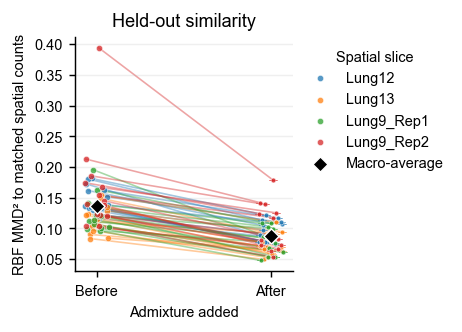

Equal-weight mean across slice/cell-type strata: 0.1369 before, 0.0868 after
Relative change: -36.6%


In [6]:
summary = test_summary
slice_names = sorted(summary["slice"].unique())
# Paired stratum-level values; lower MMD² means closer to the real spatial counts.
fig, ax = plt.subplots(figsize=(3.6, 2.6))
x_before, x_after = 0, 1
slice_colors = dict(zip(slice_names, plt.get_cmap("tab10").colors))
rng = np.random.default_rng(1729)
for slice_name, group in summary.groupby("slice", sort=True):
    jitter = rng.uniform(-0.07, 0.07, size=len(group))
    color = slice_colors[slice_name]
    for j, (_, row) in enumerate(group.iterrows()):
        ax.plot([x_before + jitter[j], x_after + jitter[j]],
                [row.mmd2_before, row.mmd2_after_mean],
                color=color, alpha=0.42, linewidth=0.9, zorder=1)
    ax.scatter(x_before + jitter, group.mmd2_before, color=color, s=12,
               alpha=0.75, edgecolor="white", linewidth=0.35, label=slice_name, zorder=2)
    ax.errorbar(x_after + jitter, group.mmd2_after_mean,
                yerr=group.mmd2_after_sd, fmt="o", color=color,
                markersize=2.7, capsize=2, alpha=0.85,
                markeredgecolor="white", markeredgewidth=0.35, zorder=3)

overall_before = macro_mmd(summary).mmd2_before
overall_after = macro_mmd(summary).mmd2_after_mean
ax.scatter([x_before, x_after], [overall_before, overall_after],
           marker="D", s=35, color="black", edgecolor="white",
           linewidth=0.8, label="Macro-average", zorder=5)
ax.set_xticks([x_before, x_after], ["Before", "After"])
ax.set_ylabel("RBF MMD² to matched spatial counts", fontsize=8)
ax.set_xlabel("Admixture added", fontsize=8)
ax.set_title("Held-out similarity", fontsize=10)
ax.grid(axis="y", alpha=0.2)
ax.tick_params(axis="both", labelsize=8)
ax.legend(title="Spatial slice", frameon=False, fontsize=8, title_fontsize=8,
          loc="upper left", bbox_to_anchor=(1.0,1.))
fig.tight_layout()
save_panel(fig, 'test_mmd_paired')
plt.show()
print(f"Equal-weight mean across slice/cell-type strata: {overall_before:.4f} before, {overall_after:.4f} after")
print(f"Relative change: {(overall_after / overall_before - 1) * 100:.1f}%")


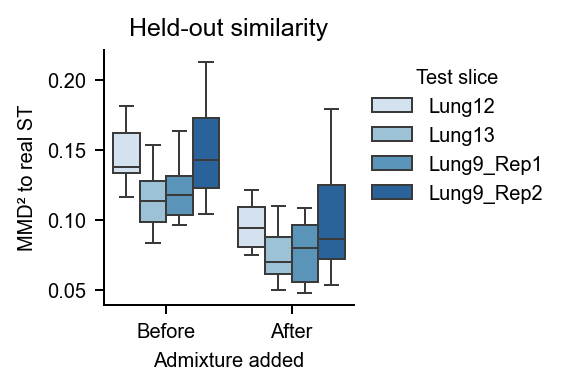

In [7]:
test_boxplot = test_summary.melt(id_vars='slice', value_vars=['mmd2_before', 'mmd2_after_mean'],
    var_name='phase', value_name='mmd2')
test_boxplot['phase'] = test_boxplot.phase.map({'mmd2_before': 'Before', 'mmd2_after_mean': 'After'})
fig, ax = plt.subplots(figsize=(3.2, 2.2), dpi=180)
sns.boxplot(data=test_boxplot, x='phase', y='mmd2', hue='slice', order=['Before','After'],
    hue_order=sorted(test_summary['slice'].unique()), palette='Blues', showfliers=False,
    width=.85, linewidth=.8, ax=ax)
ax.set(xlabel='Admixture added', ylabel='MMD² to real ST', title='Held-out similarity')
ax.tick_params(labelsize=8)
ax.legend(title='Test slice', frameon=False, fontsize=8, title_fontsize=8,
          loc='upper left', bbox_to_anchor=(1.0,1.))
fig.tight_layout()
save_panel(fig, 'test_mmd_boxplot')
plt.show()


## Method comparisons

No method runs are launched here. These panels require predictions generated
from `BENCHMARK_ROOT/slices/` and read only:

- `BENCHMARK_ROOT/syndri/<slice>_syndri_predictions.h5ad`: `admix_probs`.
- `BENCHMARK_ROOT/resolvi/<slice>.h5ad`: `resolvi_corrected_counts`.
- `BENCHMARK_ROOT/split/merged_h5ad/<slice>.h5ad`: `split_purified_counts_X`.
- `BENCHMARK_ROOT/celladmix/<slice>.h5ad`: `celladmix_corrected_counts`.
- `BENCHMARK_ROOT/ovrlpy/<slice>.h5ad`: `ovrlpy_corrected_counts_vsi_lt_0_7` by default (or the 0.5 layer selected with `OVRLPY_VSI_THRESHOLD`).

All four slices are required per method by default. Supplied cell/gene IDs and
input counts must match this simulation; old tau-based outputs are rejected.
Caches detect new prediction files automatically. Rerun this data cell and
the desired plotting cells after results arrive, or add `method_metrics` to
`RESULTS_TO_RECOMPUTE` to rebuild these metrics explicitly.

PR scores are SYNDRI probabilities, or `1 - corrected/admixed` for other
methods. Binarized variants remove all or keep all counts using each method's
pooled best-F1 cutoff. Best-F1 thresholds are descriptive test-set summaries,
not independently validated operating thresholds. Removal-fraction panels
use `SYNDRI_REMOVAL_THRESHOLD` for SYNDRI. AP and trapezoidal AUPRC are reported
separately. CellAdmix and ovrlpy use the same count-based removal scores and best-F1 binarization as ResolVI and SPLIT; native cell-level VSI is not used as a gene-level probability. Ovrlpy counts remove transcripts whose pixel VSI falls below the configured threshold.

Curves use full-resolution scores for metrics and at most 2,000
points plus the best-F1 point for display. Raw is omitted from PR curves;
positive prevalence is the constant-score ranking baseline.

**Fresh SYNDRI training:** these inputs use a new model trained with the
whole-gene lambda=0.25 sampler, the original train/validation split and
training hyperparameters, and milestone 29. The original 1,000-epoch
learning-rate horizon is retained while training stops after milestone
29. ResolVI and RCTD/SPLIT use the original Figure 3 method recipes.
Job IDs and settings are recorded in
`BENCHMARK_ROOT/manifests/method_jobs.json`. A separate renderer refreshes the method panels after the cellAdmix array completes.
Per-method caches retain completed methods when another method becomes available;
missing methods remain marked as awaiting predictions. Rerun the method data and
plotting cells to refresh results manually.


In [8]:
method_availability = availability(BENCHMARK_ROOT, ovrlpy_threshold=OVRLPY_VSI_THRESHOLD)
display(method_availability.pivot(index='slice', columns='method', values='status'))
removal_results, method_curve_data, pr_metric_summary = benchmark_metrics(
    BENCHMARK_ROOT, FIGURE_DIR, threshold=SYNDRI_REMOVAL_THRESHOLD,
    max_points=2000, recompute='method_metrics' in RESULTS_TO_RECOMPUTE,
    require_complete_methods=REQUIRE_COMPLETE_METHODS, ovrlpy_threshold=OVRLPY_VSI_THRESHOLD)
pr_data = method_curve_data.loc[method_curve_data.curve.eq('PR')].copy()
roc_data = method_curve_data.loc[method_curve_data.curve.eq('ROC') & method_curve_data.method.eq('Syndri')]
raw_results = removal_results.loc[removal_results.method.eq('Raw')]
positive_prevalence = raw_results.n_positive_entries.sum()/raw_results.n_observed_entries.sum()
print(f'New test-set positive prevalence: {positive_prevalence:.3f}')
print('No method runs are submitted by this notebook.')
display(pr_metric_summary)


method,CellAdmix,ResolVI,SPLIT,Syndri,ovrlpy
slice,,,,,
Lung12,available,available,available,available,available
Lung13,available,available,available,available,available
Lung9_Rep1,available,available,available,available,available
Lung9_Rep2,available,available,available,available,available


New test-set positive prevalence: 0.319
No method runs are submitted by this notebook.


,method,auprc,average_precision,positive_prevalence,best_f1,best_f1_threshold
0,ResolVI,0.635465,0.635207,0.318642,0.677706,0.638507
1,ResolVI (binarized),0.724635,0.537353,0.318642,0.677706,0.638507
2,Syndri,0.864171,0.864168,0.318642,0.773223,0.714226
3,Syndri (binarized),0.807630,0.666469,0.318642,0.773223,0.714226
4,SPLIT,0.569515,0.566115,0.318642,0.578364,0.259204
5,SPLIT (binarized),0.648344,0.434579,0.318642,0.578364,0.259204
6,CellAdmix,0.449914,0.365319,0.318642,0.483288,0.000000
7,CellAdmix (binarized),0.659321,0.318642,0.318642,0.483288,0.000000
8,ovrlpy,0.295784,0.317558,0.318642,0.483288,0.000000
9,ovrlpy (binarized),0.659321,0.318642,0.318642,0.483288,0.000000


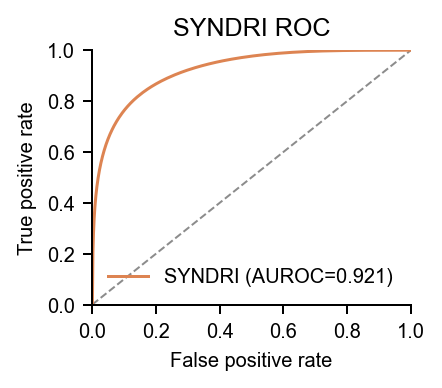

In [9]:
fig, ax = plt.subplots(figsize=(2.5, 2.2), dpi=180)
ax.plot([0,1], [0,1], '--', color='0.55', linewidth=.8)
if roc_data.empty:
    awaiting(ax, 'Awaiting fresh SYNDRI\npredictions')
else:
    ax.plot(roc_data.x, roc_data.y, color=curve_colors['Syndri'], linewidth=1.2,
            label=f"SYNDRI (AUROC={roc_data.metric_value.iloc[0]:.3f})")
    ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set(xlim=(0,1), ylim=(0,1), xlabel='False positive rate', ylabel='True positive rate', title='SYNDRI ROC')
ax.tick_params(labelsize=8)
fig.tight_layout()
save_panel(fig, 'syndri_roc')
plt.show()


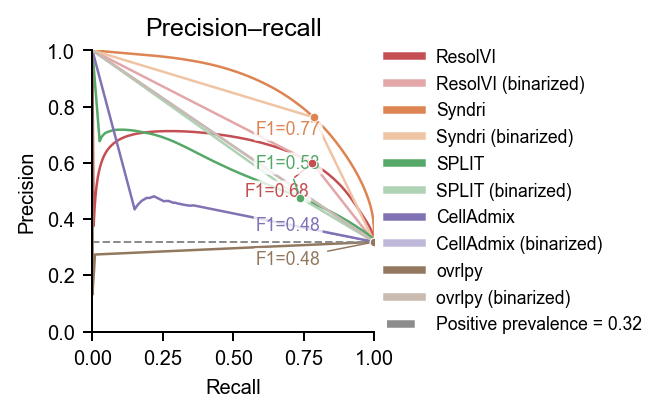

In [10]:
from matplotlib.legend_handler import HandlerLine2D
pr_fig, pr_ax = plt.subplots(figsize=(2.9,2.2), dpi=180)
# Annotate best F1 only for the unbinarized methods.
f1_annotation_offsets = {
    'ResolVI': (0.54, 0.48),
    'Syndri': (0.58, 0.70),
    'SPLIT': (0.58, 0.58),
    'CellAdmix': (0.58, 0.36),
    'ovrlpy': (0.58, 0.24),
}
for method in pr_method_order:
    method_pr = pr_data.loc[pr_data['method'].eq(method)].sort_values('x', kind='stable')
    if method_pr.empty:
        if not method.endswith(' (binarized)'):
            pr_ax.plot([], [], color=curve_colors[method], lw=1, label=f'{method} (awaiting)')
        continue
    auprc_value = float(method_pr['auprc'].iloc[0])
    pr_ax.plot(method_pr['x'], method_pr['y'], color=curve_colors[method], lw=1,
               label=method)

    # Place the exact cached best-F1 value at the highest-F1 point retained in
    # the thinned curve. The plotted point is approximate; the score is exact.
    best_f1 = float(method_pr['best_f1'].iloc[0])
    if np.isfinite(best_f1) and method in set(method_order) - {'Raw'}:
        plotted_f1 = 2 * method_pr['x'] * method_pr['y'] / (method_pr['x'] + method_pr['y'])
        plotted_f1 = plotted_f1.replace([np.inf, -np.inf], np.nan).fillna(0)
        best_point = method_pr.iloc[int(np.argmax(plotted_f1.to_numpy()))]
        pr_ax.scatter([best_point['x']], [best_point['y']], s=12,
                      color=curve_colors[method], edgecolor='white', linewidth=0.4,
                      zorder=4)
        pr_ax.annotate(
            f'F1={best_f1:.2f}',
            xy=(best_point['x'], best_point['y']),
            xytext=f1_annotation_offsets.get(method, (0.5, 0.5)),
            textcoords='data', fontsize=7, color=curve_colors[method],
            bbox={'boxstyle': 'round,pad=0.12', 'facecolor': 'white',
                  'edgecolor': 'none', 'alpha': 0.8},
            arrowprops={'arrowstyle': '-', 'color': curve_colors[method], 'lw': 0.6},
            annotation_clip=True,
        )
pr_ax.axhline(positive_prevalence, color='0.55', ls='--', lw=.8,
    label=f'Positive prevalence = {positive_prevalence:.2f}')
if pr_data.empty:
    awaiting(pr_ax, 'Awaiting fresh\nmethod predictions')
pr_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Recall', ylabel='Precision')
pr_ax.set_title('Precision–recall', fontsize=10)
pr_ax.set_xlabel('Recall', fontsize=8)
pr_ax.set_ylabel('Precision', fontsize=8)
pr_ax.tick_params(axis='both', labelsize=8)
leg = pr_ax.legend(frameon=False, loc='center left', fontsize=7,
                   bbox_to_anchor=(1.02, 0.5), borderaxespad=0)
for line in leg.get_lines():
    line.set_linewidth(3.0)
# pr_ax.grid(True, alpha=0.2)
pr_fig.subplots_adjust(left=0.14, right=0.68, bottom=0.17, top=0.88)
save_panel(pr_fig, 'method_pr_curves')
pr_fig.savefig(FIGURE_DIR / 'Figure3_pr-curve.svg')
plt.show()


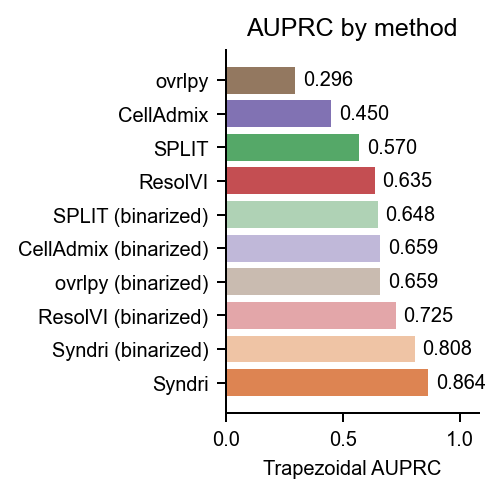

In [26]:
auprc_plot = pr_metric_summary.dropna(subset=['auprc']).sort_values('auprc', ascending=True)
fig, ax = plt.subplots(figsize=(2.8, max(2.2, 0.23*len(auprc_plot)+0.5)), dpi=180)
if auprc_plot.empty:
    awaiting(ax)
    ax.set_yticks([])
else:
    bars = ax.barh(auprc_plot.method, auprc_plot.auprc,
        color=[curve_colors[m] for m in auprc_plot.method])
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.invert_yaxis()
ax.set(xlim=(0,1.08), xlabel='Trapezoidal AUPRC', title='AUPRC by method')
ax.tick_params(labelsize=8)
ax.spines[['right','top']].set_visible(False)
fig.tight_layout()
save_panel(fig, 'method_auprc')
plt.show()


In [27]:
def plot_test_metric(metric, ylabel, title, stem):
    ylabel = ylabel.replace('Fraction of known added counts removed', 'Fraction of known added\ncounts removed').replace('Fraction of original counts removed', 'Fraction of original\ncounts removed')
    fig, ax = plt.subplots(figsize=(3.2,2.4), dpi=180)
    for x, method in enumerate(method_order):
        values = removal_results.loc[removal_results.method.eq(method), metric].dropna().to_numpy(float)
        if len(values):
            color = curve_colors[method]
            ax.boxplot([values], positions=[x], widths=.6, showfliers=False, patch_artist=True,
                boxprops={'facecolor': color, 'alpha': .65}, medianprops={'color': 'black', 'linewidth': .8},
                whiskerprops={'color': color}, capprops={'color': color})
            rng = np.random.default_rng(91827+x)
            ax.scatter(x+rng.uniform(-.1,.1,len(values)), values, s=14,
                       color=color, edgecolor='white', linewidth=.4, zorder=3)
        else:
            ax.text(x,.5,'awaiting',rotation=90,ha='center',va='center',color='0.45',fontsize=8)
    ax.set_xticks(range(len(method_order)), method_order, rotation=40, ha='right')
    ax.set(xlim=(-.55,len(method_order)-.45), ylim=(-.02,1.02), ylabel=ylabel, title=title)
    ax.tick_params(labelsize=8)
    fig.tight_layout()
    save_panel(fig, stem)
    plt.show()


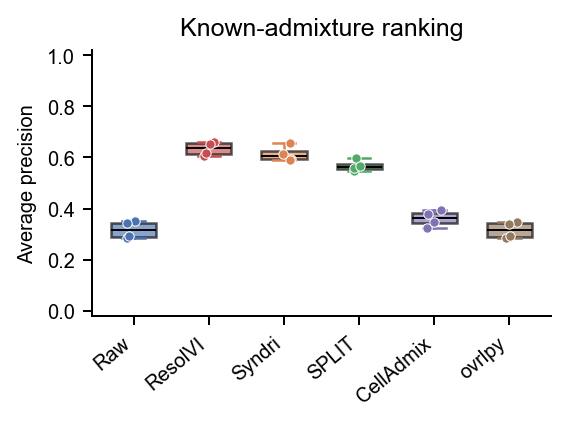

In [28]:
plot_test_metric('auprc', 'Average precision', 'Known-admixture ranking', 'removal_average_precision')


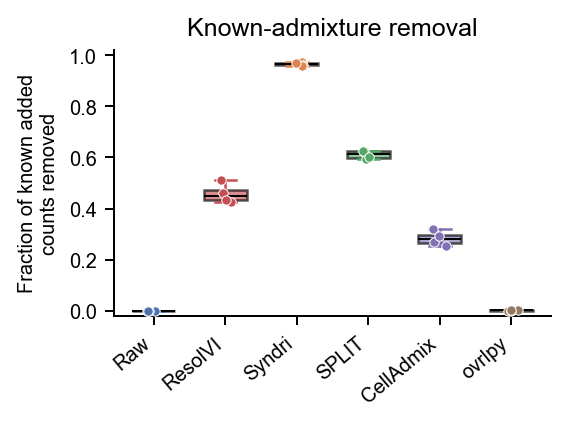

In [29]:
plot_test_metric('known_removed_fraction', 'Fraction of known added counts removed', 'Known-admixture removal', 'known_admixture_removed')


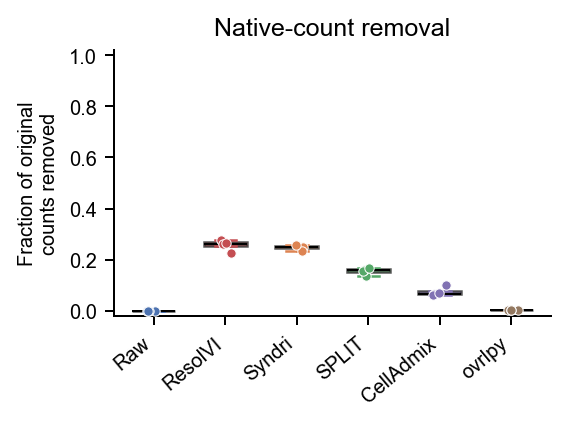

In [30]:
plot_test_metric('unadmixed_removed_fraction', 'Fraction of original counts removed', 'Native-count removal', 'native_counts_removed')


,method,best_f1,best_f1_threshold
0,ResolVI,0.677706,0.638507
1,ResolVI (binarized),0.677706,0.638507
2,Syndri,0.773223,0.714226
3,Syndri (binarized),0.773223,0.714226
4,SPLIT,0.578364,0.259204
5,SPLIT (binarized),0.578364,0.259204
6,CellAdmix,0.483288,0.000000
7,CellAdmix (binarized),0.483288,0.000000
8,ovrlpy,0.483288,0.000000
9,ovrlpy (binarized),0.483288,0.000000


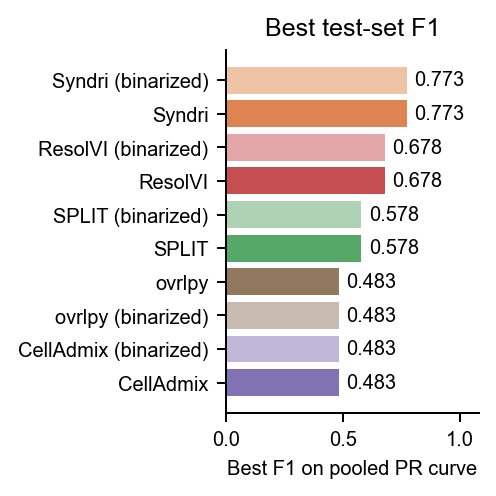

In [31]:
display(pr_metric_summary[['method','best_f1','best_f1_threshold']])
f1_plot = pr_metric_summary.dropna(subset=['best_f1']).sort_values('best_f1')
fig, ax = plt.subplots(figsize=(2.8, max(2.2, 0.23*len(f1_plot)+0.5)), dpi=180)
if f1_plot.empty:
    awaiting(ax)
    ax.set_yticks([])
else:
    bars = ax.barh(f1_plot.method, f1_plot.best_f1, color=[curve_colors[m] for m in f1_plot.method])
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
ax.set(xlim=(0,1.08), xlabel='Best F1 on pooled PR curve', title='Best test-set F1')
ax.tick_params(labelsize=8)
ax.spines[['right','top']].set_visible(False)
fig.tight_layout()
save_panel(fig, 'method_best_f1')
plt.show()


## Marker-gene co-detection

The same three ranked marker genes per cell type, aliases, family order,
log1p display, and shared color scale as the original figure. Each entry is
the fraction of **all selected cells** detecting both genes, irrespective of
cell-type labels. Compare the complete unique scRNA-seq reference, the saved
optimized test slice, and its exactly matched real recipients.

Change `COMPARISON_SLICE` in the configuration cell to choose another test
slice. The three-marker display panel differs from the full unique-marker
panel used for calibration diagnostics.

Set `WEIGHTED_CODETECTION_ROW_NORMALIZE = True` in the heatmap cell to
divide each matrix row by its sum across all displayed marker genes,
including the diagonal. Nonzero rows then sum to one; zero-sum rows stay
zero. This shows the relative co-detection pattern within each row, rather
than the absolute joint-detection fraction. Row normalization can make the
displayed matrix asymmetric. It is applied before optional `log1p` (after
which row sums need not remain one). Raw cached fractions are reused,
and normalized figure exports use a `_row_normalized` suffix.


Using donor-pool-fraction simulation: lambda_max=0.25
Loaded cached co-detection matrices: /home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_PoolFraction/Figure3_SyndriSIM_Lung12_pool_fraction_lambda0p25_codetection.csv


,gene aliases
cell_type,
T CD4+,"BTG1, FOXP3, IL7R"
T CD8+,"GZMH, CD8B, CD8A"
NK,"GNLY, XCL2, PRF1"
B cells,"MS4A1, CD37, CXCR5"
Plasmablast,"JCHAIN, FKBP11, CD38"
Monocyte,"TIMP1, S100A8, TNFRSF1B"
Macrophage,"C1QB, MMP19, GPX1"
DC,"COTL1, HLA-DPB1, HLA-DPA1"
Neutrophil,"IL1R2, ADGRG3, CXCR1"


/home/jwinchel/Syndri/figures/outputs/Figure3_SyndriSIM_PoolFraction


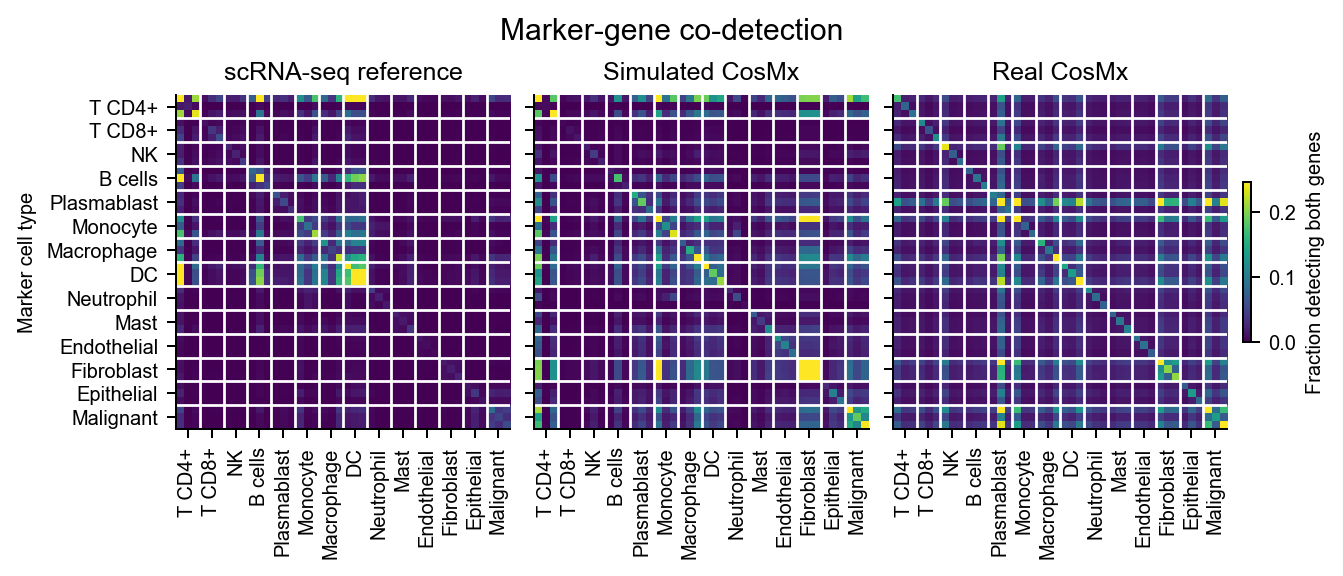

In [23]:
# Co-detection for the donor-pool-fraction test simulation (selected lambda_max = 0.25).
# Run this cell independently; it does not require the MMD or PR cells above.
from pathlib import Path
import hashlib
import json

import anndata as ad
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

WEIGHTED_CODETECTION_SLICE = COMPARISON_SLICE  # Lung12, Lung13, Lung9_Rep1, or Lung9_Rep2.
WEIGHTED_CODETECTION_RECOMPUTE = 'coexpression_matrix' in RESULTS_TO_RECOMPUTE  # True rebuilds this cell's cache only.
WEIGHTED_CODETECTION_LOG1P = False # Match the existing heatmap's log(1 + fraction) display.
WEIGHTED_CODETECTION_ROW_NORMALIZE = False # True divides each row by its sum (including the diagonal).
# Row normalization is applied before optional log1p; zero-sum rows stay zero.
WEIGHTED_CODETECTION_BATCH_SIZE = 4096
WEIGHTED_CODETECTION_GENES_PER_TYPE = 3
WEIGHTED_CODETECTION_REPO = Path(globals().get('REPO', '/home/jwinchel/Syndri'))
WEIGHTED_CODETECTION_DATA = DATA_ROOT
WEIGHTED_CODETECTION_ROOT = BENCHMARK_ROOT
WEIGHTED_CODETECTION_FIGURE_DIR = Path(globals().get(
    'FIGURE_DIR', WEIGHTED_CODETECTION_REPO / 'figures' / 'outputs'
))
WEIGHTED_CODETECTION_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTED_CODETECTION_MARKERS = (
    WEIGHTED_CODETECTION_DATA / 'results/markers/pydeseq2/candidate_cell_type_markers_deseq2.csv'
)
weighted_codetection_paths = {
    'scRNA-seq reference': WEIGHTED_CODETECTION_DATA / 'spillover-benchmark/test_admixture/train_val_sc_reference_unique.h5ad',
    'Simulated ST (weighted)': WEIGHTED_CODETECTION_ROOT / 'slices' / f'{WEIGHTED_CODETECTION_SLICE}.h5ad',
    'Real CosMx': WEIGHTED_CODETECTION_DATA / 'results/final' / f'st_integrated_slice-{WEIGHTED_CODETECTION_SLICE}.h5ad',
}
weighted_codetection_selection = json.loads(
    (WEIGHTED_CODETECTION_ROOT / 'search' / 'selected_parameters.json').read_text()
)
weighted_codetection_lambda_max = float(weighted_codetection_selection['lambda_max'])
weighted_codetection_lambda_tag = f'{weighted_codetection_lambda_max:g}'.replace('.', 'p')
weighted_codetection_stem = (
    f'Figure3_SyndriSIM_{WEIGHTED_CODETECTION_SLICE}_pool_fraction_'
    f'lambda{weighted_codetection_lambda_tag}_codetection'
)
print(f'Using donor-pool-fraction simulation: lambda_max={weighted_codetection_lambda_max:g}')
weighted_codetection_cache_path = WEIGHTED_CODETECTION_FIGURE_DIR / f'{weighted_codetection_stem}.csv'
weighted_codetection_families = [
    ('Lymphoid', ['T CD4+', 'T CD8+', 'Treg', 'NK', 'B cells', 'Plasmablast']),
    ('Myeloid / innate', ['Monocyte', 'Macrophage', 'DC', 'Neutrophil', 'Mast']),
    ('Stromal / vascular', ['Endothelial', 'Fibroblast']),
    ('Epithelial', ['Epithelial']),
    ('Malignant', ['Malignant']),
]


def weighted_codetection_metadata(path):
    # Read metadata only, without loading the real data's correction layers.
    with h5py.File(path, 'r') as handle:
        group = handle['obs']
        ids = pd.Index(ad.io.read_elem(group[group.attrs['_index']])).astype(str)
        label = 'cell_type_harmonized' if 'cell_type_harmonized' in group else 'cell_type'
        obs = pd.DataFrame({'cell_type': np.asarray(ad.io.read_elem(group[label])).astype(str)}, index=ids)
        if 'matched_st_id' in group:
            obs['matched_st_id'] = np.asarray(ad.io.read_elem(group['matched_st_id'])).astype(str)
        var = ad.io.read_elem(handle['var'])
    if not obs.index.is_unique or not var.index.is_unique:
        raise ValueError(f'Cell and gene IDs must be unique: {path}')
    return obs, var


def weighted_codetection_matrix(path, selected_rows, gene_indices, n_genes):
    # X contains the native SC counts, combined synthetic counts, or raw real
    # counts, respectively. Every selected cell contributes to every gene pair.
    pair_counts = np.zeros((len(gene_indices), len(gene_indices)), dtype=np.int64)
    selected_rows = np.sort(np.asarray(selected_rows, dtype=np.int64))
    if not len(selected_rows):
        raise ValueError(f'No selected cells in {path}')
    processed = 0
    with h5py.File(path, 'r') as handle:
        matrix = handle['X']
        for start in range(0, int(selected_rows[-1]) + 1, WEIGHTED_CODETECTION_BATCH_SIZE):
            stop = min(start + WEIGHTED_CODETECTION_BATCH_SIZE, int(selected_rows[-1]) + 1)
            rows = selected_rows[np.searchsorted(selected_rows, start):np.searchsorted(selected_rows, stop)] - start
            if not len(rows):
                continue
            if isinstance(matrix, h5py.Group):
                if matrix.attrs.get('encoding-type') != 'csr_matrix':
                    raise ValueError(f'Expected a CSR count matrix in {path}')
                pointers = matrix['indptr'][start:stop + 1]
                lo, hi = int(pointers[0]), int(pointers[-1])
                batch = sparse.csr_matrix((matrix['data'][lo:hi], matrix['indices'][lo:hi],
                                           pointers - lo), shape=(stop - start, n_genes))
                detected = (batch[rows][:, gene_indices] > 0).toarray()
            else:
                detected = matrix[start:stop, :][rows][:, gene_indices] > 0
            detected = detected.astype(np.int64)
            pair_counts += detected.T @ detected
            processed += len(rows)
    if processed != len(selected_rows):
        raise AssertionError(f'Not all selected cells were processed: {path}')
    return pair_counts / processed


weighted_codetection_metadata_by_dataset = {
    name: weighted_codetection_metadata(path) for name, path in weighted_codetection_paths.items()
}
weighted_codetection_rows = {
    name: np.arange(len(obs)) for name, (obs, _) in weighted_codetection_metadata_by_dataset.items()
}
# Match the real recipient cells exactly, including the simulation's Treg exclusion.
# No cell-type filtering is applied to individual matrix entries.
weighted_codetection_matches = weighted_codetection_metadata_by_dataset['Simulated ST (weighted)'][0]['matched_st_id']
weighted_codetection_real_rows = weighted_codetection_metadata_by_dataset['Real CosMx'][0].index.get_indexer(weighted_codetection_matches)
if (weighted_codetection_real_rows < 0).any() or not weighted_codetection_matches.is_unique:
    raise ValueError('Simulated recipients must have unique matches in the real slice.')
weighted_codetection_rows['Real CosMx'] = np.sort(weighted_codetection_real_rows)
weighted_codetection_common_genes = set.intersection(*(
    set(var.index) for _, var in weighted_codetection_metadata_by_dataset.values()
))
weighted_codetection_common_types = set.intersection(*(
    set(obs.iloc[weighted_codetection_rows[name]].cell_type)
    for name, (obs, _) in weighted_codetection_metadata_by_dataset.items()
))
weighted_codetection_type_order = [ct for _, types in weighted_codetection_families for ct in types
                                 if ct in weighted_codetection_common_types]
if weighted_codetection_common_types - set(weighted_codetection_type_order):
    raise ValueError('A shared cell type is missing from the configured Figure 2 family order.')
# Use exactly the existing heatmap's marker ranking: padj, then decreasing LFC.
weighted_codetection_candidates = pd.read_csv(WEIGHTED_CODETECTION_MARKERS).dropna(
    subset=['cell_type', 'gene', 'padj']
).sort_values(['cell_type', 'padj', 'log2FoldChange'], ascending=[True, True, False], kind='stable')
weighted_codetection_aliases = weighted_codetection_metadata_by_dataset['scRNA-seq reference'][1]['gene_symbol'].astype(str).to_dict()
weighted_codetection_axis_rows = []
for weighted_ct in weighted_codetection_type_order:
    weighted_ranked = weighted_codetection_candidates.loc[
        weighted_codetection_candidates.cell_type.eq(weighted_ct), 'gene'
    ].astype(str).drop_duplicates()
    weighted_selected = [gene for gene in weighted_ranked if gene in weighted_codetection_common_genes
                         and weighted_codetection_aliases.get(gene, '').strip()
                         and weighted_codetection_aliases[gene].lower() != 'nan'][:WEIGHTED_CODETECTION_GENES_PER_TYPE]
    if len(weighted_selected) != WEIGHTED_CODETECTION_GENES_PER_TYPE:
        raise ValueError(f'{weighted_ct}: not enough shared marker genes with aliases.')
    weighted_codetection_axis_rows.extend(
        {'cell_type': weighted_ct, 'gene_id': gene, 'alias': weighted_codetection_aliases[gene]}
        for gene in weighted_selected
    )
weighted_codetection_axis = pd.DataFrame(weighted_codetection_axis_rows)
if weighted_codetection_axis.empty:
    raise ValueError('No shared marker cell types were found.')
weighted_codetection_signature = hashlib.sha256(json.dumps({
    'version': 2, 'slice': WEIGHTED_CODETECTION_SLICE,
    'sampler': 'donor_type_weighted_pool_fraction', 'lambda_max': weighted_codetection_lambda_max,
    'genes': weighted_codetection_axis_rows, 'matrix': 'X', 'real_cells': 'matched recipients',
    'inputs': [(str(path.resolve()), path.stat().st_size, path.stat().st_mtime_ns)
               for path in [*weighted_codetection_paths.values(), WEIGHTED_CODETECTION_MARKERS]],
}, sort_keys=True).encode()).hexdigest()
weighted_codetection_cache = None
if weighted_codetection_cache_path.exists() and not WEIGHTED_CODETECTION_RECOMPUTE:
    weighted_saved = pd.read_csv(weighted_codetection_cache_path)
    weighted_required_columns = {'dataset', 'row_index', 'column_index', 'double_positive_fraction',
                                 'n_cells', 'selection_signature'}
    if (weighted_required_columns.issubset(weighted_saved.columns)
            and len(weighted_saved) == 3 * len(weighted_codetection_axis) ** 2
            and weighted_saved.selection_signature.eq(weighted_codetection_signature).all()
            and set(weighted_saved.dataset) == set(weighted_codetection_paths)
            and not weighted_saved.duplicated(['dataset', 'row_index', 'column_index']).any()):
        weighted_codetection_cache = weighted_saved
        print(f'Loaded cached co-detection matrices: {weighted_codetection_cache_path}')
if weighted_codetection_cache is None:
    weighted_codetection_frames = []
    weighted_n = len(weighted_codetection_axis)
    for weighted_name, weighted_path in weighted_codetection_paths.items():
        weighted_obs, weighted_var = weighted_codetection_metadata_by_dataset[weighted_name]
        weighted_gene_indices = weighted_var.index.get_indexer(weighted_codetection_axis.gene_id)
        weighted_matrix = weighted_codetection_matrix(
            weighted_path, weighted_codetection_rows[weighted_name], weighted_gene_indices, len(weighted_var)
        )
        weighted_codetection_frames.append(pd.DataFrame({
            'dataset': weighted_name, 'row_index': np.repeat(np.arange(weighted_n), weighted_n),
            'column_index': np.tile(np.arange(weighted_n), weighted_n),
            'double_positive_fraction': weighted_matrix.ravel(),
            'gene_1_alias': np.repeat(weighted_codetection_axis.alias.to_numpy(), weighted_n),
            'gene_2_alias': np.tile(weighted_codetection_axis.alias.to_numpy(), weighted_n),
            'n_cells': len(weighted_codetection_rows[weighted_name]),
            'selection_signature': weighted_codetection_signature,
        }))
        print(f'{weighted_name}: {len(weighted_codetection_rows[weighted_name]):,} cells')
    weighted_codetection_cache = pd.concat(weighted_codetection_frames, ignore_index=True)
    weighted_codetection_cache.to_csv(weighted_codetection_cache_path, index=False)
weighted_codetection_axis.to_csv(
    WEIGHTED_CODETECTION_FIGURE_DIR / f'{weighted_codetection_stem}_genes.csv', index=False
)
display(weighted_codetection_axis.groupby('cell_type', sort=False).alias.agg(', '.join).to_frame('gene aliases'))
weighted_codetection_matrices = {
    name: weighted_codetection_cache.loc[weighted_codetection_cache.dataset.eq(name)].pivot(
        index='row_index', columns='column_index', values='double_positive_fraction'
    ).to_numpy(float) for name in weighted_codetection_paths
}
# Keep cached joint-detection fractions unchanged; normalization is display-only.
weighted_codetection_plot_matrices = {}
for weighted_name, weighted_matrix in weighted_codetection_matrices.items():
    if WEIGHTED_CODETECTION_ROW_NORMALIZE:
        weighted_row_sums = weighted_matrix.sum(axis=1, keepdims=True)
        weighted_matrix = np.divide(
            weighted_matrix, weighted_row_sums, out=np.zeros_like(weighted_matrix),
            where=weighted_row_sums > 0,
        )
    weighted_codetection_plot_matrices[weighted_name] = weighted_matrix
weighted_codetection_display = {
    name: np.log1p(matrix) if WEIGHTED_CODETECTION_LOG1P else matrix
    for name, matrix in weighted_codetection_plot_matrices.items()
}
weighted_codetection_colorbar_label = (
    'Row-normalized co-detection' if WEIGHTED_CODETECTION_ROW_NORMALIZE
    else 'Fraction detecting both genes'
)
if WEIGHTED_CODETECTION_LOG1P:
    weighted_codetection_colorbar_label = (
        'log(1 + row-normalized co-detection)' if WEIGHTED_CODETECTION_ROW_NORMALIZE
        else 'log(1 + co-detection fraction)'
    )
# Distinct figure filenames preserve the original unnormalized exports.
weighted_codetection_plot_stem = weighted_codetection_stem + (
    '_row_normalized' if WEIGHTED_CODETECTION_ROW_NORMALIZE else ''
)
# One shared color scale makes the three panels directly comparable.
weighted_codetection_vmax = max(float(np.percentile(matrix,99)) for matrix in weighted_codetection_display.values()) or 1.
weighted_codetection_sizes = weighted_codetection_axis.groupby('cell_type', sort=False).size()
weighted_codetection_centers = np.cumsum(weighted_codetection_sizes) - weighted_codetection_sizes.to_numpy() / 2 - .5
weighted_codetection_fig, weighted_codetection_axes = plt.subplots(
    1, 3, figsize=(7.35, 2.8), dpi=180, constrained_layout=True
)
for weighted_ax, (weighted_name, weighted_matrix) in zip(weighted_codetection_axes, weighted_codetection_display.items()):
    weighted_image = weighted_ax.imshow(weighted_matrix, cmap='viridis', vmin=0,
                                        vmax=weighted_codetection_vmax, interpolation='nearest')
    weighted_title = (rf'Simulated CosMx' if weighted_name == 'Simulated ST (weighted)' else weighted_name)
    weighted_ax.set_title(weighted_title, fontsize=10)
    weighted_ax.set_xticks(weighted_codetection_centers, weighted_codetection_sizes.index,
                          rotation=90, ha='center', fontsize=8)
    weighted_ax.set_yticks(weighted_codetection_centers, weighted_codetection_sizes.index, fontsize=8)
    if weighted_ax is weighted_codetection_axes[0]:
        weighted_ax.set_ylabel('Marker cell type', fontsize=8)
    else:
        weighted_ax.tick_params(axis='y', labelleft=False)
    for weighted_boundary in np.cumsum(weighted_codetection_sizes.to_numpy())[:-1] - .5:
        weighted_ax.axhline(weighted_boundary, color='white', linewidth=1.1)
        weighted_ax.axvline(weighted_boundary, color='white', linewidth=1.1)
weighted_colorbar = weighted_codetection_fig.colorbar(
    weighted_image, ax=weighted_codetection_axes, shrink=.42, pad=.015
)
weighted_colorbar.set_label(
    weighted_codetection_colorbar_label, fontsize=8
)
weighted_colorbar.ax.tick_params(labelsize=8)
weighted_codetection_fig.suptitle(f'Marker-gene co-detection', fontsize=12, y=1.08)
# for weighted_extension in ['png', 'pdf', 'svg']:
    # weighted_codetection_fig.savefig(
    #     WEIGHTED_CODETECTION_FIGURE_DIR / f'{weighted_codetection_plot_stem}.{weighted_extension}',
    #     dpi=400, bbox_inches='tight'
    # )
weighted_codetection_fig.savefig(FIGURE_DIR / 'Figure3_codetection.svg')
print(FIGURE_DIR)
plt.show()


## Directed cell-type adjacency

Use the same test slice, real recipients, and Figure 2 family order as
co-detection. Build directed 6-nearest-neighbor graphs and calculate log2
observed/expected neighbor-pair enrichment. The diagonal is the mean of the
real and simulated values.

For a pair with indices i < j, the main panel places simulated A[i,j] above
the diagonal and **the same direction** real A[i,j] at the mirrored lower
position. The second panel compares A[j,i]. Thus both directions are retained
without averaging them together. The query type is defined by the stated
ordering, rather than by the visual row in the mirrored triangle.


In [25]:
adjacency_cell_type_order, adjacency_matrices = adjacency(
    BENCHMARK_ROOT, SPATIAL_DIR, COMPARISON_SLICE, FIGURE_DIR,
    k=6, eps=1e-8, recompute='cell_type_adjacency' in RESULTS_TO_RECOMPUTE)
real_adjacency = adjacency_matrices['Real ST slice']
simulated_adjacency = adjacency_matrices['Simulated ST slice']
coexpression_cell_type_families = weighted_codetection_families
print('Adjacency order:', adjacency_cell_type_order)
print('Maximum real/simulated difference:', float(np.max(np.abs(real_adjacency-simulated_adjacency))))
print('The simulation retains the real recipient coordinates and labels, so matching adjacency is expected.')


Adjacency order: ['T CD4+', 'T CD8+', 'NK', 'B cells', 'Plasmablast', 'Monocyte', 'Macrophage', 'DC', 'Neutrophil', 'Mast', 'Endothelial', 'Fibroblast', 'Epithelial', 'Malignant']
Maximum real/simulated difference: 0.0
The simulation retains the real recipient coordinates and labels, so matching adjacency is expected.


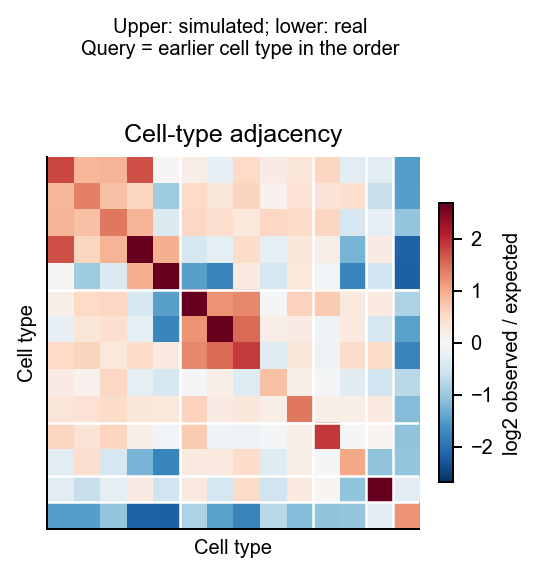

In [29]:
from matplotlib.colors import TwoSlopeNorm
n_types = len(adjacency_cell_type_order)
all_adjacency_values = np.r_[real_adjacency.ravel(), simulated_adjacency.ravel()]
color_limit = max(1., float(np.nanpercentile(np.abs(all_adjacency_values),98)))
adjacency_norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)

def plot_directional_adjacency(real, simulated, title, stem, direction):
    i,j = np.triu_indices(n_types,1)
    displayed = np.full((n_types,n_types),np.nan)
    displayed[i,j] = simulated[i,j]
    displayed[j,i] = real[i,j]  # Mirror the same directed pair for a fair comparison.
    d = np.diag_indices(n_types)
    displayed[d] = (real[d]+simulated[d])/2
    fig, ax = plt.subplots(figsize=(3.4,3.),dpi=180)
    image = ax.imshow(displayed,cmap='RdBu_r',norm=adjacency_norm,interpolation='nearest')
    # ax.set_xticks(range(n_types),adjacency_cell_type_order,rotation=90,ha='center',fontsize=8)
    # ax.set_yticks(range(n_types),adjacency_cell_type_order,fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set(xlabel='Cell type',ylabel='Cell type',title=title)
    boundary = 0
    for _,types in coexpression_cell_type_families:
        boundary += sum(ct in adjacency_cell_type_order for ct in types)
        if 0 < boundary < n_types:
            ax.axhline(boundary-.5,color='white',linewidth=1.)
            ax.axvline(boundary-.5,color='white',linewidth=1.)
    colorbar = fig.colorbar(image,ax=ax,fraction=.046,pad=.04,shrink=.75)
    colorbar.set_label('log2 observed / expected',fontsize=8)
    colorbar.ax.tick_params(labelsize=8)
    fig.suptitle(f'Upper: simulated; lower: real\n{direction}',fontsize=8,y=1.04)
    fig.tight_layout()
    save_panel(fig,stem)
    fig.savefig(FIGURE_DIR / 'Figure3_adjacency.svg')
    plt.show()

plot_directional_adjacency(real_adjacency,simulated_adjacency,'Cell-type adjacency',
    f'{COMPARISON_SLICE}_adjacency_main','Query = earlier cell type in the order')


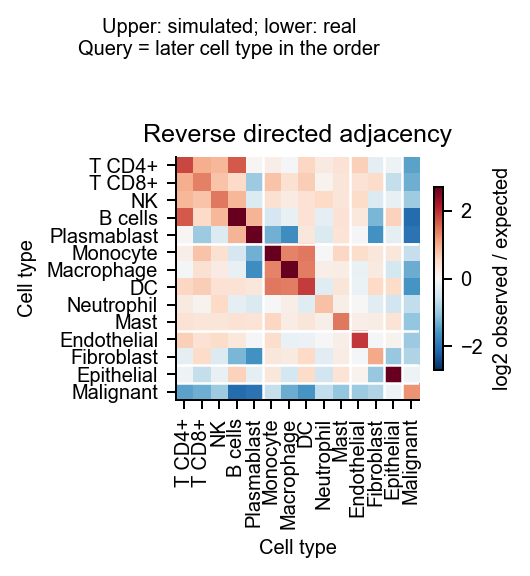

In [27]:
plot_directional_adjacency(real_adjacency.T,simulated_adjacency.T,'Reverse directed adjacency',
    f'{COMPARISON_SLICE}_adjacency_reverse','Query = later cell type in the order')
